# 📘 6.2 Errors in Newton–Cotes Methods

### Deciding whether a numerical integral is accurate enough

Notebook 6.1 showed how the trapezoidal and Simpson's 1/3 rules convert
sampled engineering data into an accumulated quantity. A numerical answer,
however, is not automatically a reliable answer.

This notebook asks four practical questions:

* What does **integration error** mean?
* Why do the trapezoidal and Simpson estimates converge at different rates?
* How can refinement studies reveal whether the result is settling?
* Which errors cannot be fixed by choosing a higher-order rule?

We continue the rocket-motor total-impulse example, then use functions with
known integrals to make the errors visible and measurable.


## Before you begin: what does $I$ mean here?

This notebook contains more integral equations than most of the course. Do not
let the notation hide the main engineering idea: **we are asking how much trust
to place in an accumulated numerical result.**

We use $I$ to represent the ideal value of a stated integral:

$$
I=\int_a^b f(x)\,\mathrm{d}x.
$$

In a mathematical example, $I$ may be known exactly. In a synthetic example, we
may calculate a very accurate reference because we created the generating
function. For a real experiment, however, the true physical value of $I$ usually
**cannot be measured directly**. It may only be estimated using sampled data,
inferred from a model, or compared with an independent reference. We therefore
use known examples to study the theory, then carry the resulting checks and
cautions into real engineering work.

You are not expected to memorise every error equation on first reading. Focus on:

1. what the symbols mean;
2. what happens when the sample spacing is reduced;
3. which assumptions make an error result valid; and
4. what a calculation can and cannot claim about a real system.

Numerical integration is useful when the required output is an **accumulation**:
for example, impulse from thrust over time, energy from power over time, or work
from force over displacement. It is not automatically useful for every dataset.
If the engineering question concerns a peak, a trend, a frequency, a local event
or a causal relationship, another analysis may be more appropriate. Start with
the physical question; use an integral only when accumulation answers it.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* distinguish signed, absolute and relative integration error;
* distinguish quadrature error from measurement, sampling and round-off error;
* explain polynomial exactness and asymptotic order of accuracy;
* state the smoothness assumptions behind classical Newton–Cotes error results;
* use a mesh-refinement study and a log–log plot to assess convergence;
* calculate conservative error bounds when derivative bounds are available;
* recognise unresolved features, non-smooth behaviour and sensor bias; and
* report numerical evidence without claiming an unknown exact answer.

### 🔗 Unit Learning Outcome Alignment

This notebook supports:

* **LO1:** Assess the suitability and limitations of numerical analysis tools.
* **LO2:** Develop defensible solutions to open-ended engineering problems.
* **LO3:** Evaluate numerical performance, error, stability and accuracy.

### 📚 Sources used in this notebook

* NIST DLMF — [Quadrature](https://dlmf.nist.gov/3.5)
* SciPy — [Integration tutorial](https://docs.scipy.org/doc/scipy/tutorial/integrate.html)
* SciPy — [`integrate.trapezoid`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.trapezoid.html)
* SciPy — [`integrate.simpson`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.simpson.html)
* NumPy — [Data types and floating-point precision](https://numpy.org/doc/stable/user/basics.types.html)


## 📂 6.2.0 How to use this notebook

This is a **pre-work content notebook**. Run every cell from top to bottom; no
cell requires editing or typed input. The examples are deterministic so that
every student sees the same results.

Notebook 6.2 studies error diagnosis. Notebook 6.3 will build on the refinement
pattern to introduce Richardson extrapolation and Romberg integration.


### 📖 Core language for 6.2

* The **exact integral** $I$ is the mathematical value of the stated integral.
* A **quadrature estimate** $Q_h$ is the value returned using spacing $h$.
* **Quadrature error** is $I-Q_h$ and comes from replacing the integrand between
  nodes with an approximation.
* **Absolute error** ignores the sign; **relative error** scales error by $|I|$.
* **Order of accuracy** describes how rapidly error decreases as $h\to0$.
* A rule's **degree of exactness** is the highest polynomial degree it integrates
  exactly, apart from floating-point effects.
* A **refinement study** repeats a calculation with progressively smaller $h$.
* The **asymptotic range** is the region where the leading theoretical error term
  dominates and the expected convergence rate is visible.


In [ ]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import quad, simpson, trapezoid

pd.set_option("display.precision", 8)
plt.rcParams["figure.figsize"] = (8.5, 5.0)


## 📂 6.2.1 One answer, several sources of disagreement

Suppose the required physical quantity is

$$
I_{\mathrm{physical}}=\int_a^b f_{\mathrm{physical}}(x)\,\mathrm{d}x.
$$

A computer instead integrates measured samples. A useful error map is:

$$
\text{reported result} - \text{physical truth}
= \text{quadrature contribution}
+ \text{data contribution}
+ \text{model/scope contribution}
+ \text{round-off contribution}.
$$

This is a **conceptual decomposition**, not a claim that each contribution is
always known or statistically independent.

| Contribution | Typical cause | Does smaller $h$ always fix it? |
|---|---|---|
| Quadrature | curve assumed between samples | Often, if the integrand is sufficiently smooth |
| Sampling | a peak or oscillation was not resolved | Only if new samples capture it |
| Measurement | noise, calibration bias, drift | No |
| Model/scope | wrong bounds, omitted physics, wrong units | No |
| Round-off | finite-precision arithmetic | No; extreme refinement can worsen it |

A method-comparison plot measures disagreement between methods. It does **not**
by itself reveal which answer is closest to physical truth.


## 📂 6.2.2 Signed, absolute and relative error

We use the convention

$$
E_h = I-Q_h.
$$

Therefore $E_h>0$ means the numerical estimate is too small, while $E_h<0$
means it is too large. The most common reported magnitudes are

$$
|E_h|=|I-Q_h|,
\qquad
\varepsilon_{\mathrm{rel}}=\frac{|I-Q_h|}{|I|},
\qquad
\varepsilon_{\%}=100\varepsilon_{\mathrm{rel}}.
$$

Relative error is not useful when $I=0$ and can be misleading when $I$ is very
close to zero. In those cases, use an absolute engineering tolerance or a
meaningful reference scale.


In [ ]:
def error_metrics(estimate, exact):
    signed = exact - estimate
    absolute = abs(signed)
    relative = np.nan if np.isclose(exact, 0.0) else absolute / abs(exact)
    return signed, absolute, relative


# A transparent test: integral of exp(x) from 0 to 1 is e - 1.
exact_exp = np.e - 1.0
x_demo = np.linspace(0.0, 1.0, 5)  # 4 equal intervals
y_demo = np.exp(x_demo)

estimates = {
    "Trapezoidal": trapezoid(y_demo, x=x_demo),
    "Simpson": simpson(y_demo, x=x_demo),
}

error_rows = []
for method, estimate in estimates.items():
    signed, absolute, relative = error_metrics(estimate, exact_exp)
    error_rows.append(
        {
            "Method": method,
            "Estimate": estimate,
            "Signed error I - Q": signed,
            "Absolute error": absolute,
            "Relative error [%]": 100 * relative,
        }
    )

display(pd.DataFrame(error_rows))


,Method,Estimate,Signed error I - Q,Absolute error,Relative error [%]
0,Trapezoidal,1.72722190,-0.00894008,0.00894008,0.5202916
1,Simpson,1.71831884,-0.00003701,0.00003701,0.0021541


## 📂 6.2.3 Degree of exactness is a precise but limited promise

For equally spaced nodes:

* the trapezoidal rule is exact for polynomials up to degree 1; and
* Simpson's 1/3 rule is exact for polynomials up to degree 3.

"Exact" means the mathematical quadrature formula matches the polynomial
integral. Floating-point calculations may still differ in their final digits.

Degree of exactness does **not** mean Simpson's rule exactly integrates every
smooth curve. It explains why a rule reproduces certain local polynomial
behaviour and helps determine its leading error term.


,Polynomial,Exact integral,Trapezoidal abs. error,Simpson abs. error
0,x^0,1.00000000,0.00000000,0.00000000
1,x^1,0.50000000,0.00000000,0.00000000
2,x^2,0.33333333,0.01041667,0.00000000
3,x^3,0.25000000,0.01562500,0.00000000
4,x^4,0.20000000,0.02070312,0.00052083
5,x^5,0.16666667,0.02571615,0.00130208
6,x^6,0.14285714,0.03060477,0.00248791


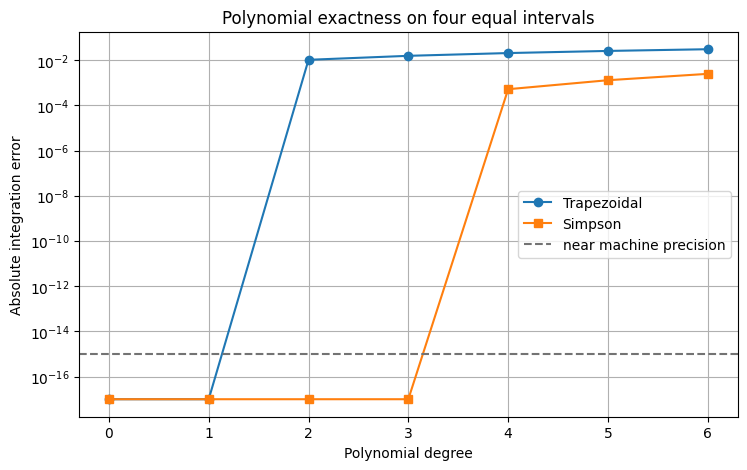

In [ ]:
degrees = np.arange(0, 7)
x_poly = np.linspace(0.0, 1.0, 5)  # 4 equal intervals
exact_poly = 1.0 / (degrees + 1)

trap_poly = np.array([
    trapezoid(x_poly**degree, x=x_poly) for degree in degrees
])
simp_poly = np.array([
    simpson(x_poly**degree, x=x_poly) for degree in degrees
])

polynomial_errors = pd.DataFrame(
    {
        "Polynomial": [f"x^{degree}" for degree in degrees],
        "Exact integral": exact_poly,
        "Trapezoidal abs. error": np.abs(exact_poly - trap_poly),
        "Simpson abs. error": np.abs(exact_poly - simp_poly),
    }
)
display(polynomial_errors)

fig, ax = plt.subplots()
ax.semilogy(
    degrees,
    np.maximum(np.abs(exact_poly - trap_poly), 1e-17),
    "o-",
    label="Trapezoidal",
)
ax.semilogy(
    degrees,
    np.maximum(np.abs(exact_poly - simp_poly), 1e-17),
    "s-",
    label="Simpson",
)
ax.axhline(1e-15, color="0.45", linestyle="--", label="near machine precision")
ax.set_xlabel("Polynomial degree")
ax.set_ylabel("Absolute integration error")
ax.set_title("Polynomial exactness on four equal intervals")
ax.set_xticks(degrees)
ax.grid(True, which="both")
ax.legend()
plt.show()


## 📂 6.2.4 Classical composite error formulas

Let $n$ equal intervals cover $[a,b]$, with

$$h=\frac{b-a}{n}.$$

If $f$ has a continuous second derivative, the composite trapezoidal error has
the form

$$
E_{T,n}=I-T_n=-\frac{b-a}{12}h^2 f''(\xi),
\qquad a<\xi<b.
$$

If $n$ is even and $f$ has a continuous fourth derivative, the composite
Simpson error has the form

$$
E_{S,n}=I-S_n=-\frac{b-a}{180}h^4 f^{(4)}(\xi),
\qquad a<\xi<b.
$$

The unknown point $\xi$ depends on the function and rule. These expressions
explain the leading powers of $h$, but usually do not give the exact error
directly.

**Interpretation:** halve $h$ within the asymptotic range and the trapezoidal
error should reduce by about $2^2=4$; Simpson error should reduce by about
$2^4=16$.


### Conditions are part of the result

The familiar $O(h^2)$ and $O(h^4)$ statements assume:

* a fixed integration interval;
* equally spaced nodes for these classical composite formulas;
* the required continuous derivatives;
* a valid panel arrangement, including even $n$ for composite Simpson 1/3; and
* sufficiently small $h$ for the leading error term to dominate.

If a function has a corner, discontinuity, very narrow peak or unresolved
oscillation, the observed behaviour may differ. A high nominal order is not a
substitute for checking the integrand and samples.


## 📂 6.2.5 Refinement study with a known integral

We now integrate $f(x)=e^x$ on $[0,1]$. Its exact integral is $e-1$, so the true
quadrature error is available. Each refinement doubles the number of intervals
and halves $h$.


,Intervals n,Spacing h,Trapezoidal error,Simpson error
0,2,0.500000,0.03564926,5.79323418e-04
1,4,0.250000,0.00894008,3.70134627e-05
2,8,0.125000,0.00223676,2.32624085e-06
3,16,0.062500,0.00055930,1.45592847e-07
4,32,0.031250,0.00013983,9.10272635e-09
5,64,0.015625,0.00003496,5.68970204e-10


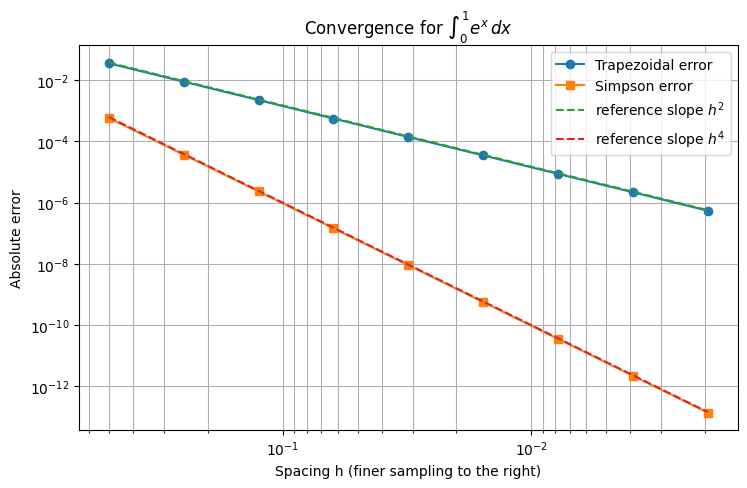

In [ ]:
interval_counts = 2 ** np.arange(1, 10)  # all even for Simpson
refinement_rows = []

for n_intervals in interval_counts:
    x = np.linspace(0.0, 1.0, n_intervals + 1)
    y = np.exp(x)
    h = 1.0 / n_intervals
    trap_estimate = trapezoid(y, x=x)
    simp_estimate = simpson(y, x=x)
    refinement_rows.append(
        {
            "Intervals n": n_intervals,
            "Spacing h": h,
            "Trapezoidal error": abs(exact_exp - trap_estimate),
            "Simpson error": abs(exact_exp - simp_estimate),
        }
    )

refinement = pd.DataFrame(refinement_rows)
display(refinement.head(6))

fig, ax = plt.subplots()
ax.loglog(
    refinement["Spacing h"],
    refinement["Trapezoidal error"],
    "o-",
    label="Trapezoidal error",
)
ax.loglog(
    refinement["Spacing h"],
    refinement["Simpson error"],
    "s-",
    label="Simpson error",
)

h_reference = refinement["Spacing h"].to_numpy()
ax.loglog(h_reference, 0.15 * h_reference**2, "--", label=r"reference slope $h^2$")
ax.loglog(h_reference, 0.01 * h_reference**4, "--", label=r"reference slope $h^4$")
ax.invert_xaxis()
ax.set_xlabel("Spacing h (finer sampling to the right)")
ax.set_ylabel("Absolute error")
ax.set_title(r"Convergence for $\int_0^1 e^x\,dx$")
ax.grid(True, which="both")
ax.legend()
plt.show()


A straight line on a log–log error plot indicates approximately

$$|E_h|\approx C h^p,$$

where the line's slope is $p$. For two successive spacings, an observed order is

$$
p_{\mathrm{obs}}
=\frac{\log(|E_h|/|E_{h/2}|)}{\log 2}.
$$

Because this calculation uses the exact error, it is a **verification test**.
In ordinary experiments the exact physical integral is usually unavailable.
Notebook 6.3 will develop a principled way to use related estimates without an
exact answer.


In [ ]:
for method in ["Trapezoidal", "Simpson"]:
    errors = refinement[f"{method} error"].to_numpy()
    observed_order = np.log(errors[:-1] / errors[1:]) / np.log(2.0)
    refinement.loc[1:, f"{method} observed p"] = observed_order

display(
    refinement[
        [
            "Intervals n",
            "Spacing h",
            "Trapezoidal observed p",
            "Simpson observed p",
        ]
    ].tail(6)
)


,Intervals n,Spacing h,Trapezoidal observed p,Simpson observed p
3,16,0.06250000,1.99971831,3.99798910
4,32,0.03125000,1.99992956,3.99949695
5,64,0.01562500,1.99998239,3.99987370
6,128,0.00781250,1.99999560,3.99996284
7,256,0.00390625,1.99999890,3.99981084
8,512,0.00195312,1.99999972,3.99927962


## 📂 6.2.6 Error bounds: useful, conservative and conditional

Since $\xi$ is unknown, replace a derivative value by a maximum over the
interval:

$$
|E_{T,n}|\leq \frac{b-a}{12}h^2
\max_{a\leq x\leq b}|f''(x)|,
$$

$$
|E_{S,n}|\leq \frac{b-a}{180}h^4
\max_{a\leq x\leq b}|f^{(4)}(x)|.
$$

For $f(x)=e^x$ on $[0,1]$, both derivative maxima equal $e$. The bounds certify
that error cannot exceed a stated value **if their assumptions hold**. They are
often larger than the actual error because one worst-case derivative value is
applied across the whole interval.


In [ ]:
n_bound = 8
h_bound = 1.0 / n_bound
x_bound = np.linspace(0.0, 1.0, n_bound + 1)
y_bound = np.exp(x_bound)

bound_comparison = pd.DataFrame(
    {
        "Method": ["Trapezoidal", "Simpson"],
        "Actual abs. error": [
            abs(exact_exp - trapezoid(y_bound, x=x_bound)),
            abs(exact_exp - simpson(y_bound, x=x_bound)),
        ],
        "Theoretical upper bound": [
            np.e * h_bound**2 / 12.0,
            np.e * h_bound**4 / 180.0,
        ],
    }
)
bound_comparison["Bound / actual"] = (
    bound_comparison["Theoretical upper bound"]
    / bound_comparison["Actual abs. error"]
)
display(bound_comparison)


,Method,Actual abs. error,Theoretical upper bound,Bound / actual
0,Trapezoidal,0.00223676,0.00353943,1.58238863
1,Simpson,0.00000233,0.00000369,1.58492002


### Designing a spacing from a tolerance

If a required absolute tolerance is $\tau$ and a derivative bound $M_2$ is
credible, the trapezoidal inequality gives

$$
h\leq\sqrt{\frac{12\tau}{(b-a)M_2}}.
$$

For Simpson's rule with derivative bound $M_4$,

$$
h\leq\left(\frac{180\tau}{(b-a)M_4}\right)^{1/4},
$$

followed by choosing an **even** number of intervals. This is a conservative
design calculation, not permission to ignore sensor bandwidth or unresolved
features.


In [ ]:
tolerance = 1e-6
interval_length = 1.0
derivative_bound = np.e

h_trap_max = np.sqrt(12.0 * tolerance / (interval_length * derivative_bound))
n_trap = int(np.ceil(interval_length / h_trap_max))

h_simp_max = (180.0 * tolerance / (interval_length * derivative_bound)) ** 0.25
n_simp = int(np.ceil(interval_length / h_simp_max))
if n_simp % 2 == 1:
    n_simp += 1

tolerance_design = pd.DataFrame(
    {
        "Method": ["Trapezoidal", "Simpson"],
        "Largest h from bound": [h_trap_max, h_simp_max],
        "Selected intervals": [n_trap, n_simp],
        "Selected samples": [n_trap + 1, n_simp + 1],
    }
)
display(tolerance_design)


,Method,Largest h from bound,Selected intervals,Selected samples
0,Trapezoidal,0.00210108,476,477
1,Simpson,0.09020789,12,13


## 📂 6.2.7 Engineering return: thrust sampling and total impulse

We reuse the deterministic teaching curve from Notebook 6.1. Because its formula
is known here, adaptive integration can create a **mathematical reference for
this synthetic model**. It is not independent physical ground truth.

The total impulse is

$$I_{\mathrm{total}}=\int_0^{10}F(t)\,\mathrm{d}t.$$


In [ ]:
def underlying_thrust_N(time_s):
    time_s = np.asarray(time_s, dtype=float)
    burn_duration_s = 10.0
    rise = 1.0 - np.exp(-2.8 * time_s)
    decay = 1.0 - np.exp(-2.2 * (burn_duration_s - time_s))
    modulation = 1.0 + 0.035 * np.sin(1.25 * time_s)
    thrust = 1180.0 * rise * decay * modulation
    return np.where((time_s >= 0.0) & (time_s <= burn_duration_s), thrust, 0.0)


impulse_reference, quad_error_estimate = quad(
    lambda time_s: float(underlying_thrust_N(time_s)),
    0.0,
    10.0,
    epsabs=1e-10,
)

sample_counts = np.array([5, 7, 9, 11, 21, 41, 81, 161])
impulse_rows = []
for sample_count in sample_counts:
    time_s = np.linspace(0.0, 10.0, sample_count)
    thrust_N = underlying_thrust_N(time_s)
    impulse_rows.append(
        {
            "Samples": sample_count,
            "h [s]": time_s[1] - time_s[0],
            "Trapezoidal error [N s]": abs(
                impulse_reference - trapezoid(thrust_N, x=time_s)
            ),
            "Simpson error [N s]": abs(
                impulse_reference - simpson(thrust_N, x=time_s)
            ),
        }
    )

impulse_refinement = pd.DataFrame(impulse_rows)
display(impulse_refinement)
print(f"Synthetic-model reference impulse: {impulse_reference:.3f} N s")
print(f"quad's numerical error estimate: {quad_error_estimate:.2e} N s")


,Samples,h [s],Trapezoidal error [N s],Simpson error [N s]
0,5,2.50000000,2007.17231705,1025.31925262
1,7,1.66666667,1079.50136019,446.79547407
2,9,1.25000000,663.95616469,216.21744723
3,11,1.00000000,445.59125871,113.87402918
4,21,0.50000000,119.61938670,10.96209603
5,41,0.25000000,30.49366324,0.78508875
6,81,0.12500000,7.66159212,0.05090175
7,161,0.06250000,1.91780649,0.00321128


Synthetic-model reference impulse: 10845.777 N s
quad's numerical error estimate: 4.02e-08 N s


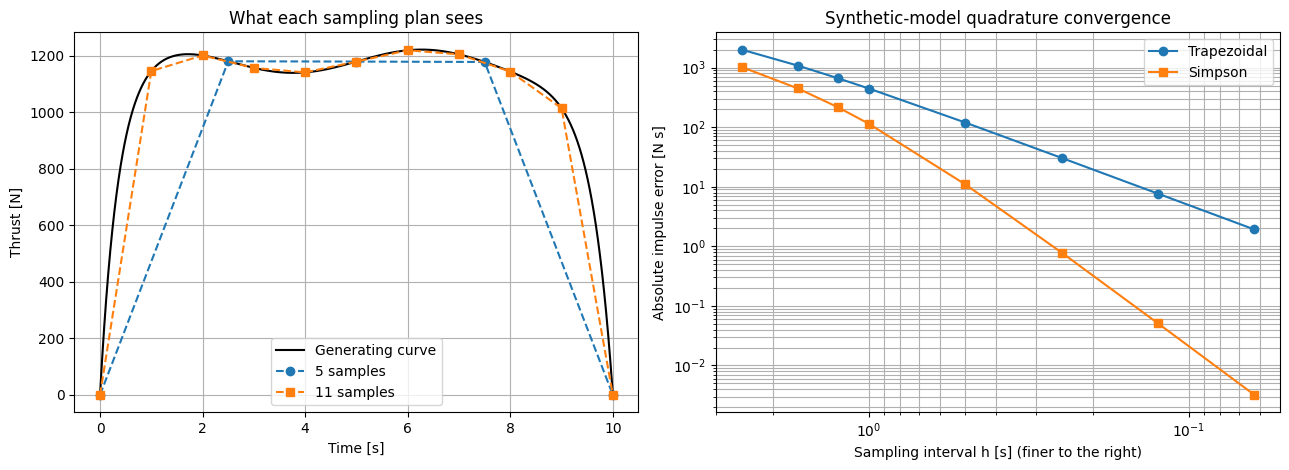

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

time_dense = np.linspace(0.0, 10.0, 1001)
axes[0].plot(time_dense, underlying_thrust_N(time_dense), color="black", label="Generating curve")
for sample_count, marker in [(5, "o"), (11, "s")]:
    time_s = np.linspace(0.0, 10.0, sample_count)
    axes[0].plot(
        time_s,
        underlying_thrust_N(time_s),
        marker=marker,
        linestyle="--",
        label=f"{sample_count} samples",
    )
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Thrust [N]")
axes[0].set_title("What each sampling plan sees")
axes[0].grid(True)
axes[0].legend()

axes[1].loglog(
    impulse_refinement["h [s]"],
    impulse_refinement["Trapezoidal error [N s]"],
    "o-",
    label="Trapezoidal",
)
axes[1].loglog(
    impulse_refinement["h [s]"],
    impulse_refinement["Simpson error [N s]"],
    "s-",
    label="Simpson",
)
axes[1].invert_xaxis()
axes[1].set_xlabel("Sampling interval h [s] (finer to the right)")
axes[1].set_ylabel("Absolute impulse error [N s]")
axes[1].set_title("Synthetic-model quadrature convergence")
axes[1].grid(True, which="both")
axes[1].legend()

plt.tight_layout()
plt.show()


The error curves need not be perfectly straight at coarse spacing. The thrust
trace contains start-up, modulation and shut-down time scales, and the leading
asymptotic error term may not yet dominate. This is why convergence should be
**observed**, not assumed from the method's name.


## 📂 6.2.8 Higher order cannot recover an unseen feature

Consider

$$f(x)=\sin^2(10\pi x),\qquad 0\leq x\leq1.$$

Its exact integral is $0.5$. If samples occur every $0.1$, every sample lands at
a zero. Both Newton–Cotes rules receive the same misleading data and return zero.

This is **sampling error**, not a failure to apply the formulas correctly. No
interpolating rule can reconstruct a feature that the samples do not reveal.


,Sampling,Trapezoidal,Simpson,Exact
0,11 samples,2.08058115e-30,2.11074935e-30,0.5
1,21 samples,5.00000000e-01,6.66666667e-01,0.5


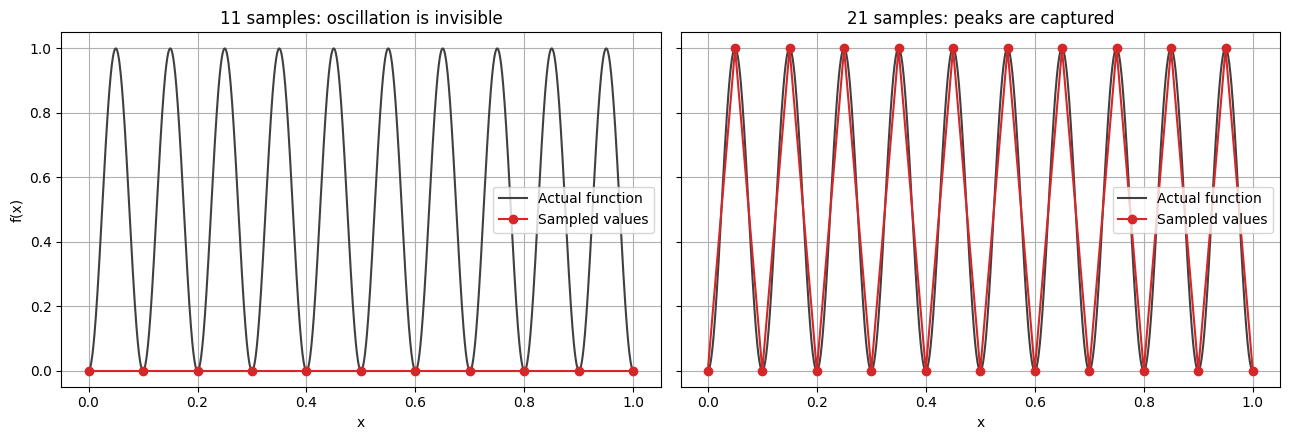

In [ ]:
def unresolved_signal(x):
    return np.sin(10.0 * np.pi * x) ** 2


x_hidden = np.linspace(0.0, 1.0, 11)
y_hidden = unresolved_signal(x_hidden)
x_visible = np.linspace(0.0, 1.0, 21)
y_visible = unresolved_signal(x_visible)
x_signal = np.linspace(0.0, 1.0, 2001)

hidden_results = pd.DataFrame(
    {
        "Sampling": ["11 samples", "21 samples"],
        "Trapezoidal": [
            trapezoid(y_hidden, x=x_hidden),
            trapezoid(y_visible, x=x_visible),
        ],
        "Simpson": [
            simpson(y_hidden, x=x_hidden),
            simpson(y_visible, x=x_visible),
        ],
        "Exact": [0.5, 0.5],
    }
)
display(hidden_results)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, x_samples, y_samples, title in [
    (axes[0], x_hidden, y_hidden, "11 samples: oscillation is invisible"),
    (axes[1], x_visible, y_visible, "21 samples: peaks are captured"),
]:
    ax.plot(x_signal, unresolved_signal(x_signal), color="0.25", label="Actual function")
    ax.plot(x_samples, y_samples, "o-", color="tab:red", label="Sampled values")
    ax.set_xlabel("x")
    ax.set_title(title)
    ax.grid(True)
    ax.legend()
axes[0].set_ylabel("f(x)")
plt.tight_layout()
plt.show()


With 21 samples, the peaks become visible. The trapezoidal estimate happens to
equal the exact integral for this specially aligned example, while Simpson's
parabolic segments overshoot and return $2/3$. This is a useful warning:
**capturing a feature is necessary, but a higher-order rule is not guaranteed to
be better on every grid.** Further refinement and independent physical knowledge
are still required.


### Practical sampling checks

Before integrating measured data:

* compare sampling rate with known physical time or length scales;
* inspect raw data in the coordinate domain;
* check whether peaks occupy multiple samples;
* use anti-alias filtering where the measurement system requires it;
* repeat measurements or compare another instrument where practical; and
* avoid interpreting agreement between two rules as proof that features were
  resolved.


## 📂 6.2.9 Smoothness matters: a corner changes convergence

The function

$$f(x)=|x-0.37|$$

is continuous but is not differentiable at $x=0.37$. The classical Simpson
$O(h^4)$ result requires a continuous fourth derivative, so it does not apply
across this corner. The rule still returns useful estimates, but its observed
convergence need not match the smooth-function promise.


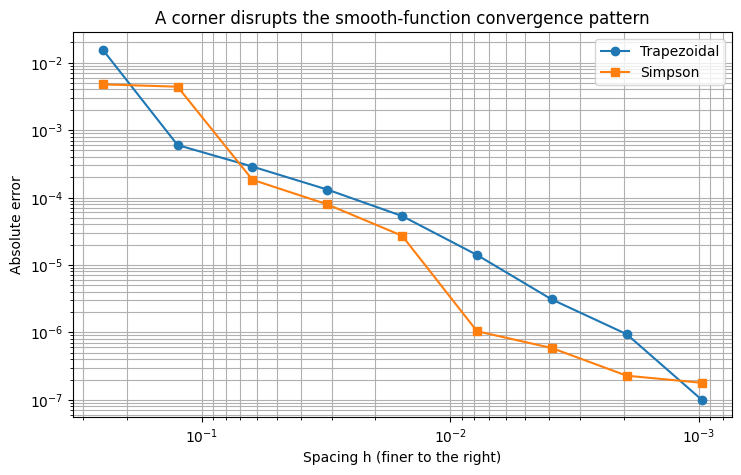

In [ ]:
corner = 0.37
exact_corner = 0.5 * corner**2 + 0.5 * (1.0 - corner) ** 2
corner_rows = []

for n_intervals in 2 ** np.arange(2, 11):
    x = np.linspace(0.0, 1.0, n_intervals + 1)
    y = np.abs(x - corner)
    corner_rows.append(
        {
            "h": 1.0 / n_intervals,
            "Trapezoidal": abs(exact_corner - trapezoid(y, x=x)),
            "Simpson": abs(exact_corner - simpson(y, x=x)),
        }
    )

corner_errors = pd.DataFrame(corner_rows)

fig, ax = plt.subplots()
ax.loglog(corner_errors["h"], corner_errors["Trapezoidal"], "o-", label="Trapezoidal")
ax.loglog(corner_errors["h"], corner_errors["Simpson"], "s-", label="Simpson")
ax.invert_xaxis()
ax.set_xlabel("Spacing h (finer to the right)")
ax.set_ylabel("Absolute error")
ax.set_title(r"A corner disrupts the smooth-function convergence pattern")
ax.grid(True, which="both")
ax.legend()
plt.show()


If the location of a genuine discontinuity or corner is known, splitting the
integration interval at that location can prevent one polynomial panel from
spanning incompatible behaviour. This does not remove the need to resolve the
feature with data.


## 📂 6.2.10 Measurement bias creates an error floor

Refining a numerical rule acts on quadrature error. It does not recalibrate a
sensor. To demonstrate, suppose thrust readings have a constant +1% gain bias:

$$F_{\mathrm{measured}}(t)=1.01F_{\mathrm{true}}(t).$$

As sampling becomes finer, the integration method converges accurately to the
integral of the **biased readings**, not to the true impulse.


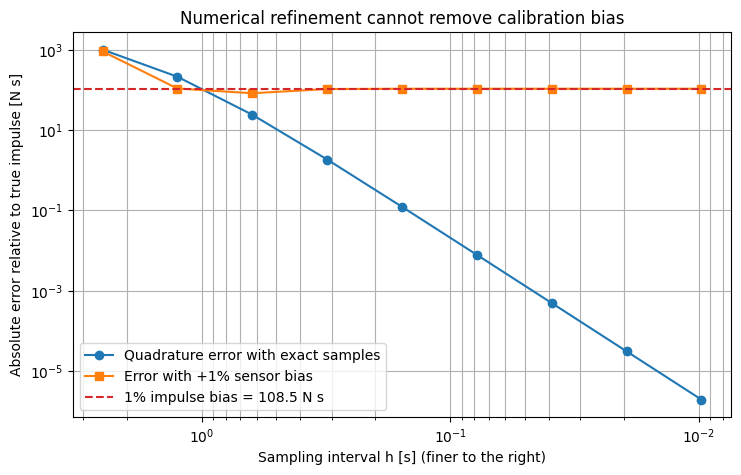

In [ ]:
bias_fraction = 0.01
bias_rows = []

for sample_count in 2 ** np.arange(2, 11) + 1:
    time_s = np.linspace(0.0, 10.0, sample_count)
    true_thrust = underlying_thrust_N(time_s)
    biased_thrust = (1.0 + bias_fraction) * true_thrust

    bias_rows.append(
        {
            "h [s]": time_s[1] - time_s[0],
            "Unbiased quadrature error": abs(
                impulse_reference - simpson(true_thrust, x=time_s)
            ),
            "Total error with +1% sensor bias": abs(
                impulse_reference - simpson(biased_thrust, x=time_s)
            ),
        }
    )

bias_study = pd.DataFrame(bias_rows)
expected_bias_floor = bias_fraction * impulse_reference

fig, ax = plt.subplots()
ax.loglog(
    bias_study["h [s]"],
    bias_study["Unbiased quadrature error"],
    "o-",
    label="Quadrature error with exact samples",
)
ax.loglog(
    bias_study["h [s]"],
    bias_study["Total error with +1% sensor bias"],
    "s-",
    label="Error with +1% sensor bias",
)
ax.axhline(
    expected_bias_floor,
    color="tab:red",
    linestyle="--",
    label=f"1% impulse bias = {expected_bias_floor:.1f} N s",
)
ax.invert_xaxis()
ax.set_xlabel("Sampling interval h [s] (finer to the right)")
ax.set_ylabel("Absolute error relative to true impulse [N s]")
ax.set_title("Numerical refinement cannot remove calibration bias")
ax.grid(True, which="both")
ax.legend()
plt.show()


In real testing, measurement **uncertainty** should be assessed with calibration
records, sensor specifications, repeat tests and an appropriate uncertainty
analysis. It should not be labelled "Newton–Cotes error".


## 📂 6.2.11 Round-off: normally small, never literally absent

NumPy's usual `float64` has machine epsilon near

$$\varepsilon_{\mathrm{machine}}\approx2.22\times10^{-16}.$$

This is the spacing from 1.0 to the next larger representable `float64` number.
It is not a universal bound on a complete calculation. Rounding accumulates
through arithmetic, and subtracting nearly equal values can lose significant
digits.

For the sample counts used in these notebooks, truncation and data quality are
generally more important than round-off. At extreme refinement, however, error
does not decrease forever.


In [ ]:
floating_point_summary = pd.DataFrame(
    {
        "Type": ["float32", "float64"],
        "Machine epsilon": [np.finfo(np.float32).eps, np.finfo(np.float64).eps],
        "Approx. decimal precision": [
            np.finfo(np.float32).precision,
            np.finfo(np.float64).precision,
        ],
    }
)
display(floating_point_summary)

decimal_example = 0.3 - 0.2 - 0.1
print(f"0.3 - 0.2 - 0.1 = {decimal_example:.18e}")
print("Close to zero?", np.isclose(decimal_example, 0.0))


,Type,Machine epsilon,Approx. decimal precision
0,float32,1.19209290e-07,6
1,float64,2.22044605e-16,15


0.3 - 0.2 - 0.1 = -2.775557561562891351e-17
Close to zero? True


## 📂 6.2.12 What if the exact answer is unknown?

Most engineering measurements do not come with $I$. A defensible study can still:

1. confirm units, bounds, ordering and missing-data handling;
2. plot the samples and inspect whether physical features are resolved;
3. compare estimates from nested sampling levels if higher-rate data exist;
4. compare two rules whose assumptions are satisfied;
5. look for a stable trend under refinement;
6. verify the implementation on separate functions with known integrals;
7. compare against conservation laws, calibration cases or independent methods;
8. separate measurement uncertainty from quadrature sensitivity; and
9. report the finest estimate together with the evidence and unresolved limits.

The difference $|Q_{h/2}-Q_h|$ is a **change between estimates**, not the true
error $|I-Q_{h/2}|$. Treating the two as equal requires additional theory and
assumptions, which Notebook 6.3 will develop.


In [ ]:
# A report-ready refinement table for the synthetic thrust example.
report_table = impulse_refinement.copy()
report_table["Trap change from previous [N s]"] = report_table[
    "Trapezoidal error [N s]"
].diff().abs()
report_table["Simpson change from previous [N s]"] = report_table[
    "Simpson error [N s]"
].diff().abs()

# In a real unknown-answer problem, report estimates and successive changes;
# the exact-error columns used above would not be available.
unknown_answer_rows = []
for sample_count in sample_counts:
    time_s = np.linspace(0.0, 10.0, sample_count)
    thrust_N = underlying_thrust_N(time_s)
    unknown_answer_rows.append(
        {
            "Samples": sample_count,
            "h [s]": time_s[1] - time_s[0],
            "Trapezoidal estimate [N s]": trapezoid(thrust_N, x=time_s),
            "Simpson estimate [N s]": simpson(thrust_N, x=time_s),
        }
    )

unknown_answer_table = pd.DataFrame(unknown_answer_rows)
for method in ["Trapezoidal", "Simpson"]:
    estimate_column = f"{method} estimate [N s]"
    unknown_answer_table[f"{method} successive change [N s]"] = (
        unknown_answer_table[estimate_column].diff().abs()
    )

display(unknown_answer_table)


,Samples,h [s],Trapezoidal estimate [N s],Simpson estimate [N s],Trapezoidal successive change [N s],Simpson successive change [N s]
0,5,2.50000000,8838.60435923,9820.45742366,NaN,NaN
1,7,1.66666667,9766.27531609,10398.98120221,927.67095686,578.52377854
2,9,1.25000000,10181.82051159,10629.55922904,415.54519550,230.57802684
3,11,1.00000000,10400.18541757,10731.90264710,218.36490598,102.34341805
4,21,0.50000000,10726.15728958,10834.81458024,325.97187200,102.91193315
5,41,0.25000000,10815.28301304,10844.99158752,89.12572346,10.17700728
6,81,0.12500000,10838.11508415,10845.72577453,22.83207112,0.73418700
7,161,0.06250000,10843.85886979,10845.77346500,5.74378563,0.04769047


### Language for reporting

Prefer:

> With 81 samples, Simpson's estimate changed by ___ N s relative to the
> preceding sampling level. The trace was visually resolved at this spacing,
> and the implementation reproduced polynomial verification cases. Sensor
> calibration uncertainty was assessed separately.

Avoid:

> The answer is exact because Simpson and trapezoidal estimates agree.

Agreement is evidence of limited **method sensitivity** for those samples. It is
not proof of physical accuracy.


## 📂 6.2.13 Optional interactive convergence view

Move the slider to change the number of equal intervals used for
$\int_0^1 e^x\,\mathrm{d}x$. The plot shows the sampled curve while the title
reports both errors. Simpson requires an even interval count, so the control
advances in steps of two.


In [ ]:
def plot_error_exploration(n_intervals=4):
    x = np.linspace(0.0, 1.0, n_intervals + 1)
    y = np.exp(x)
    x_dense = np.linspace(0.0, 1.0, 501)

    trap_value = trapezoid(y, x=x)
    simpson_value = simpson(y, x=x)
    trap_error = abs(exact_exp - trap_value)
    simpson_error = abs(exact_exp - simpson_value)

    fig, ax = plt.subplots()
    ax.plot(x_dense, np.exp(x_dense), color="black", label=r"$e^x$")
    ax.plot(x, y, "o-", color="tab:blue", label=f"{n_intervals + 1} samples")
    ax.fill_between(x, 0.0, y, color="tab:blue", alpha=0.15)
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.set_title(
        f"n={n_intervals}: trapezoidal error={trap_error:.2e}, "
        f"Simpson error={simpson_error:.2e}"
    )
    ax.grid(True)
    ax.legend()
    plt.show()


try:
    import ipywidgets as widgets

    widgets.interact(
        plot_error_exploration,
        n_intervals=widgets.IntSlider(
            value=4,
            min=2,
            max=40,
            step=2,
            description="Intervals",
            continuous_update=False,
        ),
    )
except ImportError:
    print("ipywidgets is unavailable; showing the four-interval case.")
    plot_error_exploration(n_intervals=4)


interactive(children=(IntSlider(value=4, continuous_update=False, description='Intervals', max=40, min=2, step…

## 📂 6.2.14 Common interpretation failures

| Failure | Why it is unsafe | Better action |
|---|---|---|
| Reporting many digits | display precision is not accuracy | Match precision to validation and uncertainty |
| Calling method disagreement "the error" | the exact value is unknown | Call it method sensitivity or estimate difference |
| Assuming Simpson is always better | smoothness and sampling assumptions may fail | Inspect convergence and the data |
| Refining interpolated data | no new physical information was added | Obtain higher-rate measurements if needed |
| Ignoring sensor bias | quadrature converges to biased data | Use calibration and uncertainty evidence |
| Applying relative error near zero | the denominator makes it unstable | Use an absolute tolerance or reference scale |
| Using a derivative bound blindly | the bound may be unknown or assumptions may fail | State how the bound was obtained |
| Treating a library warning as a nuisance | it may signal invalid inputs or arithmetic | investigate before suppressing it |


## 📂 6.2.15 Useful packages and functions

| Package | Function or technique | Purpose | Important caution |
|---|---|---|---|
| `scipy.integrate` | `trapezoid` | integrate sampled data with composite trapezoids | ordering and sampling quality remain your responsibility |
| `scipy.integrate` | `simpson` | integrate sampled data with composite Simpson's rule | classical order requires smoothness and a valid grid |
| `scipy.integrate` | `quad` | reference calculation for a callable function | its error estimate is numerical, not measurement uncertainty |
| `numpy` | `abs`, `isclose` | calculate magnitudes and tolerant comparisons | choose tolerances with physical meaning |
| `numpy` | `finfo` | inspect floating-point limits | machine epsilon is not total algorithm error |
| `pandas` | `DataFrame`, `diff` | build refinement and successive-change tables | a successive change is not automatically true error |
| `matplotlib` | `loglog` | diagnose power-law convergence | only use positive error magnitudes on log axes |


## 📂 6.2.16 Engineering workflow and summary

A defensible integration-error workflow is:

1. define the physical quantity, bounds, units and accuracy requirement;
2. separate quadrature questions from data and modelling questions;
3. verify code on functions with known integrals and relevant smoothness;
4. visualise the samples and identify important physical scales;
5. perform a refinement study using genuinely finer information where possible;
6. inspect observed convergence rather than assuming nominal order;
7. calculate an error bound when credible derivative bounds exist;
8. assess calibration, bias, noise and repeatability separately;
9. compare results with independent physical or numerical evidence; and
10. report estimates, sensitivity, assumptions and remaining limitations.

**Key result:** for sufficiently smooth functions on valid equal grids, composite
trapezoidal error behaves as $O(h^2)$ and composite Simpson error as $O(h^4)$.
Those are conditional convergence statements. They do not guarantee that sampled
experimental data represent the physical signal.


## 📚 References

* NIST Digital Library of Mathematical Functions, *Quadrature*, Section 3.5.
* SciPy developers, *Integration (`scipy.integrate`)*, stable documentation.
* NumPy developers, *Data types* and floating-point precision, stable documentation.

## 🤖 AI Acknowledgment

Generative AI was used to help structure explanations, develop deterministic
teaching examples and review code. The teaching team remains responsible for the
mathematics, engineering interpretation, source selection and final notebook.
